# Network Interdiction Analysis

This notebook uses the metrics and plot conventions in
[the quantum-preconditioning notebook](../../Gurobi_QP/notebooks/analysis.ipynb),
implemented in `Gurobi_QP/qp_gurobi/utils.py`.
It reads saved results only. It does not run solvers or submit hardware jobs.

For a **feasible interdiction**, let $f$ be its surviving maximum flow and
$f^*$ the exact optimum for the same graph and budget. Lower flow is better.

- **Approx Ratio - 1:** $f/f^*-1$. Zero is optimal; smaller is better.
- **Performance (%):** $100[1-(f-f^*)/|f^*|]$, exactly as computed by the
  reference notebook's `plot_performance_distribution`. 100% is optimal;
  larger is better. This score can be negative and is not clipped.
- **Time to an epsilon-optimal threshold:** the first recorded time when
  $f(t)\le f^*+|f^*|\epsilon$. This requires an incumbent history.

Zero optima are excluded from relative metrics, as in the reference notebook.
QUBO-energy scores and optimal-sample probabilities are not used as the
solution-quality axes here.

There are three plots: the five-method objective comparison, the classical
performance distribution, and one recorded incumbent trajectory.

In [1]:
from pathlib import Path
import sys
import importlib

import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "utils.py").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import utils
utils = importlib.reload(utils)
utils.apply_plot_style()

FIGURES_DIR = REPO_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
transfer = utils.load_transfer_objectives(REPO_ROOT / "results/parameter_transfer.csv")
df = utils.load_results(REPO_ROOT / "results/slide_instances_sa.csv")

print(f"Transfer: {len(transfer)} rows, {transfer['group'].nunique()} test graphs")
print(f"Classical comparison: {len(df)} graph-budget pairs")
print(f"Zero-optimum rows excluded: transfer={(transfer['opt_nip'] == 0).sum()}, "
      f"classical={(df['Opt_NIP'] == 0).sum()}")

Transfer: 60 rows, 6 test graphs
Classical comparison: 27 graph-budget pairs
Zero-optimum rows excluded: transfer=0, classical=0


## Approximation ratio minus one

Same original-objective measure as the reference notebook's
`plot_ratio_minus_one`, with methods on the x-axis instead of a penalty sweep.
Columns compare $p=1$ and $p=2$ on the same six test graphs (18–21 qubits,
$B=1$). Points show means and bars show standard errors.

**These are final solutions after greedy repair. All five methods reach the
optimum on all six graphs, so this plot shows a tie. Greedy alone is also
optimal on these cases.** The result does not establish a quantum improvement.
The saved transfer CSV does not contain each method's best raw feasible flow,
so this notebook does not substitute a Hamiltonian score for raw solution quality.

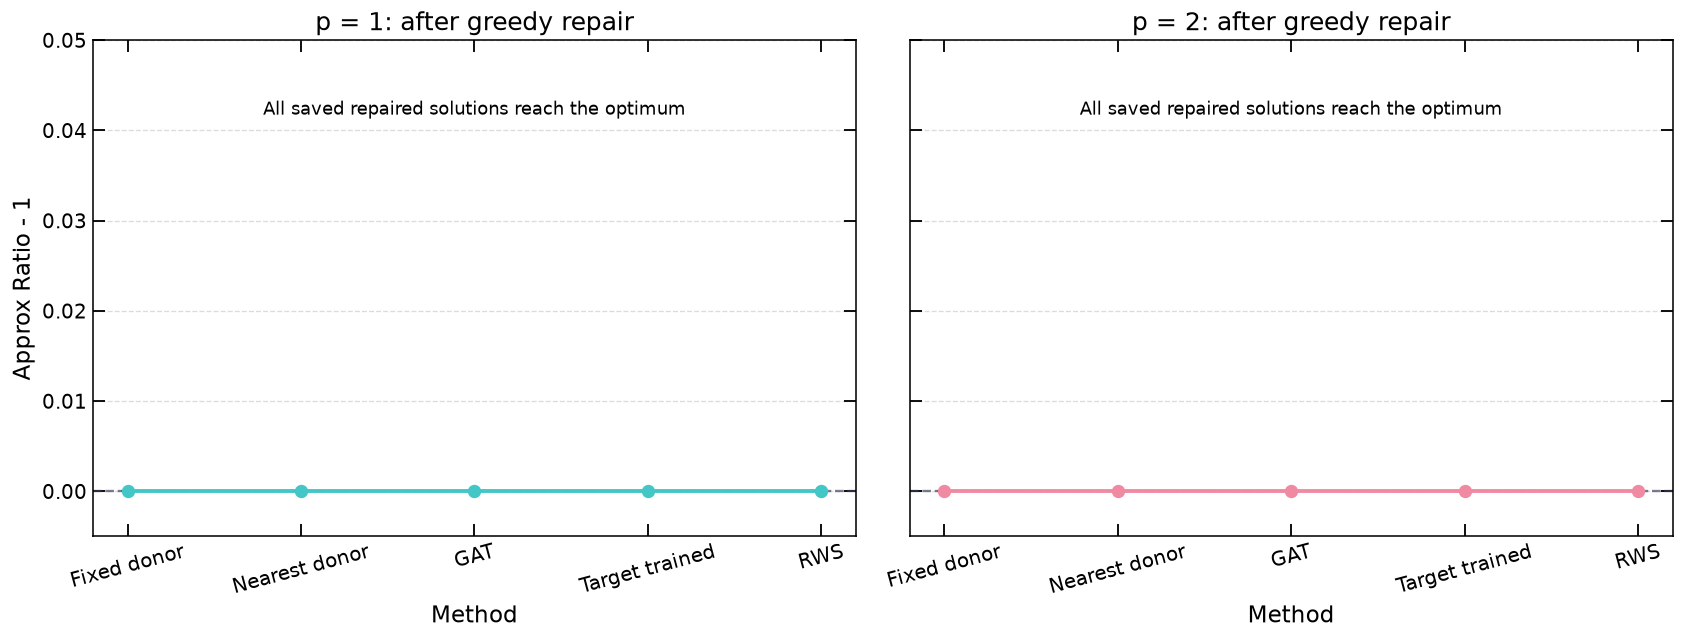

In [2]:
fig_transfer = utils.plot_transfer_objective_gap(transfer)
plt.savefig(FIGURES_DIR / "transfer_objective_gap.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURES_DIR / "transfer_objective_gap.pdf", bbox_inches="tight")
plt.show()

## Performance distribution

Same original-objective performance definition as the reference notebook.
The top strip shows scores of at least 99.999%, using its threshold.
Labels give the number meeting that threshold out of the valid rows for
each method and family. The lower panel shows the remaining scores on a
logarithmic distance-from-100% axis. Black bars show mean scores, including
the optimal rows.

This figure uses the 27 saved classical graph-budget pairs. It compares
greedy from scratch, simulated annealing followed by repair, and random
initialization followed by repair. Missing solver results remain missing.

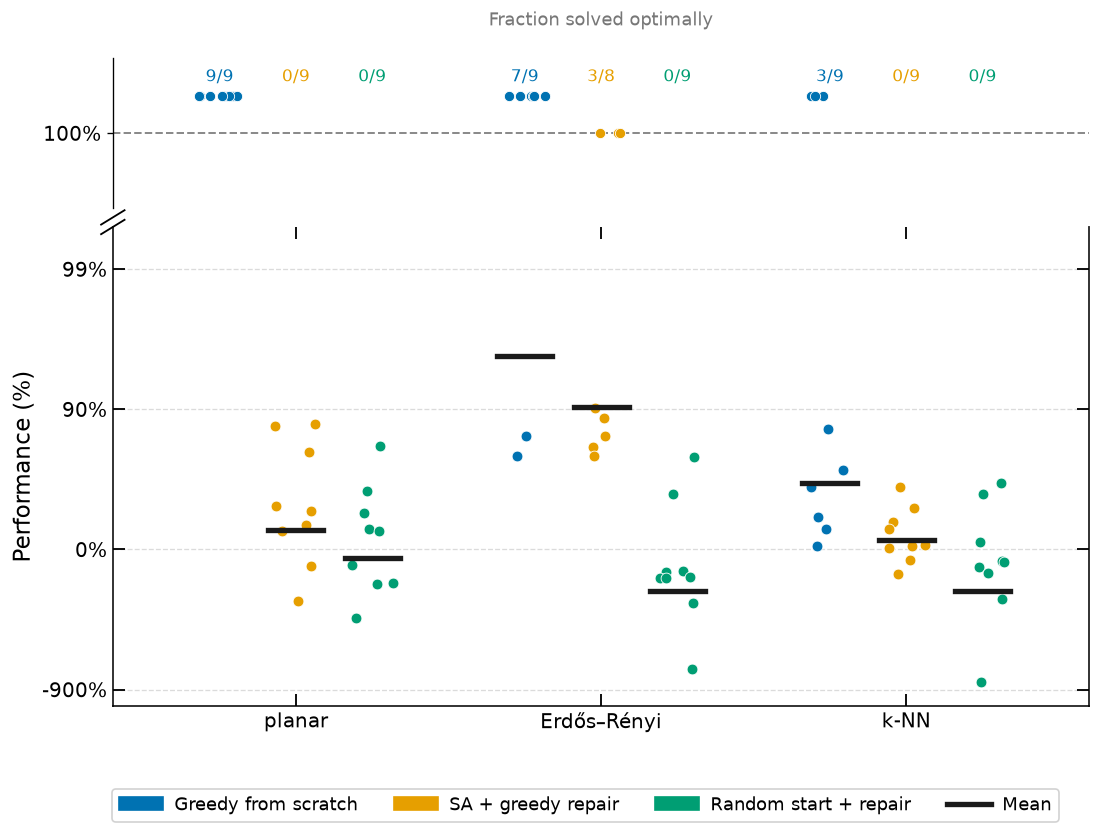

In [3]:
fig_performance = utils.plot_performance_distribution(df)
plt.savefig(FIGURES_DIR / "performance_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Incumbent trajectory

The y-axis is **Approx Ratio - 1**, as in the reference notebook's
`plot_mipsol_ratio_minus_one`. Only Gurobi has a saved incumbent history.
The other markers show final results at recorded completion times; they
are not time-to-threshold observations. The y-axis uses a symmetric log
scale so exact zero remains visible.

This historical CSV records one Gurobi thread. It is not a timing comparison
with the fresh eight-thread decomposition run. Recorded solver times exclude
model construction; they do not establish an end-to-end speedup.

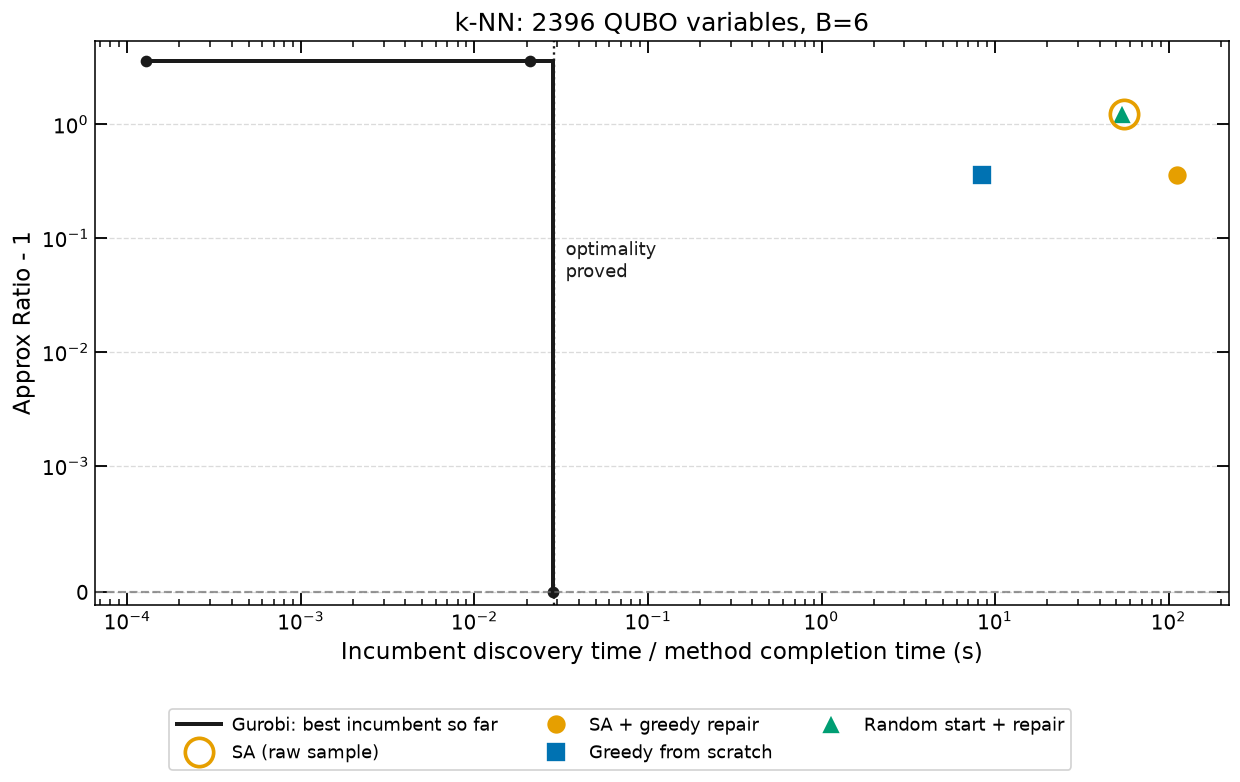

In [4]:
fig_trajectory = utils.plot_incumbent_trajectory(df, "100_6.2dnnflow", 6)
plt.savefig(FIGURES_DIR / "gurobi_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()

## Timing plots that need additional recorded data

The reference notebook also reports time to an epsilon-optimal threshold,
penalized average time (PAR), and scaling with problem size. For failed runs,
its PAR value is the method's runtime plus the paired baseline runtime
(penalty factor one). Successful runs contribute their first threshold-hit time.

The saved five-method QAOA results have final scores and component timings,
but no original-objective incumbent histories or paired baseline runtimes.
Those timing comparisons cannot be reconstructed from this data. They are
omitted here. Generating the missing measurements requires a separately
requested experiment.